# Paso 8 · Evaluación, optimización, decisión y auditoría de equidad

| | |
|---|---|
| **IDs del enunciado** | F4, IA3.3 (comparación final), IA1.3 (auditoría ética), R1 |
| **Fase** | F4 · Evaluar y optimizar (CRISP-DM: *Evaluation*) |
| **Historia** | HU-08 · Sprint S7 |
| **Entregable** | este notebook + `Back/models/modelo_final.joblib` + `Back/models/model_card.json` |

**Este notebook no reentrena.** El modelo servido lo produce `Back/train.py` (única fuente de verdad,
ADR-001); aquí se leen sus predicciones out-of-fold y de test, de modo que **cada cifra coincide con la
model card por construcción** (lo comprueba la última sección).

**Aprendizaje de la unidad (Módulo 2 · Unidad 3 y Unidad 1).** Optimizar un modelo de crédito no es
maximizar el AUC: es elegir una **política de decisión** con costos explícitos (aprobar, revisar,
rechazar), verificar que las probabilidades estén **calibradas**, auditar la **equidad** con intervalos de
confianza y poder **explicar** cada decisión.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from credit_risk import config
from credit_risk.data import cargar_procesados, separar_xy
from credit_risk.models import Costos, Umbrales, costo_binario, curvas, estimador_base, metricas
from credit_risk.prediccion import cargar_artefactos
from credit_risk.reporting import PALETA, SERIE, figura_front, leer_json

art = cargar_artefactos()
card, artefacto = art["card"], art["artefacto"]
oof = pd.read_parquet(config.MODEL_DIR / "oof_predictions.parquet")
pred_te = pd.read_parquet(config.MODEL_DIR / "test_predictions.parquet")
train, test = cargar_procesados()
X_tr, y_tr = separar_xy(train)
X_te, y_te = separar_xy(test)
U = Umbrales(**card["umbrales"])
print(f"Modelo {card['version']} · {card['algoritmo']} · variante de equidad: {card['variante_equidad']}")
print(f"Entrenado el {card['fecha_entrenamiento']} en {card['duracion_entrenamiento_s']} s")
print("Umbrales (regla de Chow):", card["umbrales"])

Modelo 2.0.0 · LogisticRegression calibrado (sigmoide, ensemble=False) · variante de equidad: reweighing
Entrenado el 2026-10-23 en 490.1 s
Umbrales (regla de Chow): {'aprobar': 0.1778, 'rechazar': 0.4667, 'bayes': 0.25}


## 1. Optimización: selección de familia e hiperparámetros (CV en train)

`RandomizedSearchCV` (8 combinaciones, CV estratificada de 5 particiones, ROC-AUC) para regresión logística
y gradient boosting. Regla de parsimonia: si el boosting no supera a la logística por al menos
0,005 de AUC, se prefiere la logística (más interpretable y con explicaciones exactas).

In [5]:
seleccion = pd.DataFrame(card["seleccion_cv_train"]).T
seleccion

,roc_auc_cv,roc_auc_cv_std,hiperparametros
Regresión logística,0.8582,0.0052,{'C': 0.031489}
Gradient Boosting (HGB),0.8525,0.0051,"{'l2_regularization': 0.133112, 'learning_rate..."


## 2. Calibración: ¿la probabilidad significa lo que dice?

Se compara el estimador base (sin calibrar) con el modelo servido (calibración sigmoide con
`ensemble=False`). Ambos se evalúan en test.

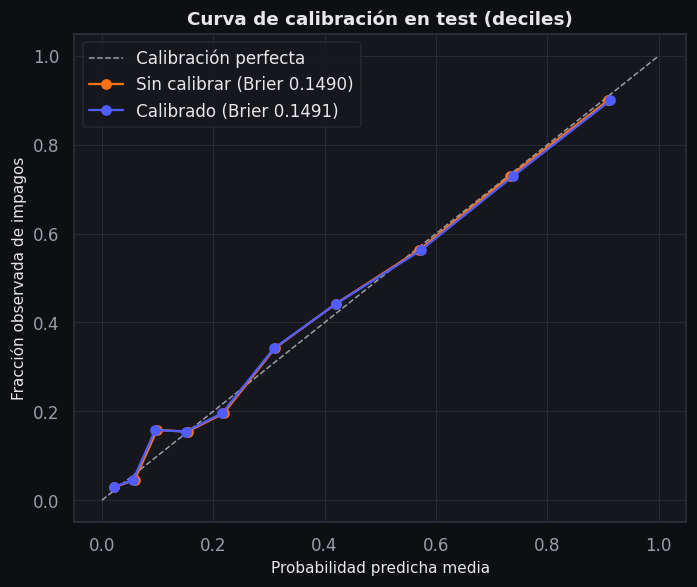

In [6]:
p_cal = pred_te["p"].to_numpy()
p_base = estimador_base(artefacto.modelo).predict_proba(X_te)[:, 1]
cb, cc = curvas(y_te, p_base), curvas(y_te, p_cal)
brier_base, brier_cal = metricas(y_te, p_base, U.bayes)["brier"], metricas(y_te, p_cal, U.bayes)["brier"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", color=PALETA["texto_suave"], lw=1, label="Calibración perfecta")
ax.plot(cb["calib_prob_media"], cb["calib_frac_positivos"], "o-", color=PALETA["programacion"],
        label=f"Sin calibrar (Brier {brier_base:.4f})")
ax.plot(cc["calib_prob_media"], cc["calib_frac_positivos"], "o-", color=PALETA["acento"],
        label=f"Calibrado (Brier {brier_cal:.4f})")
ax.set(title="Curva de calibración en test (deciles)", xlabel="Probabilidad predicha media",
       ylabel="Fracción observada de impagos")
ax.legend()
plt.show()
figura_front("calibracion", "Curva de calibración en test (deciles)",
             {"series": [{"nombre": f"Sin calibrar (Brier {brier_base:.4f})", "x": cb["calib_prob_media"], "y": cb["calib_frac_positivos"]},
                         {"nombre": f"Calibrado (Brier {brier_cal:.4f})", "x": cc["calib_prob_media"], "y": cc["calib_frac_positivos"]}],
              "referencias": [{"tipo": "diagonal", "etiqueta": "Calibración perfecta"}]},
             ejes={"x": "Probabilidad predicha media", "y": "Fracción observada de impagos"}, clave="calibracion",
             opciones={"formato_x": "pct", "formato_y": "pct"})

**Interpretación.** Ambas curvas siguen de cerca la diagonal: la regresión logística ya sale bien calibrada
de fábrica (Brier 0,1490) y la calibración sigmoide la conserva (0,1491) sin mejorarla. Se mantiene porque la
regla de Chow exige probabilidades calibradas por construcción —también si mañana la familia ganadora fuera un
boosting— y porque con `ensemble=False` las contribuciones siguen siendo exactas. Calibrar no era necesario
aquí; verificarlo, sí.

## 3. Política de decisión: aprobar, revisar o rechazar

Con costos por unidad de exposición (ADR-002) — aprobar a quien no paga cuesta la LGD, rechazar a un buen
pagador cuesta el margen y revisar cuesta el tiempo del analista, la demora y su error residual — los
umbrales óptimos salen en forma cerrada.

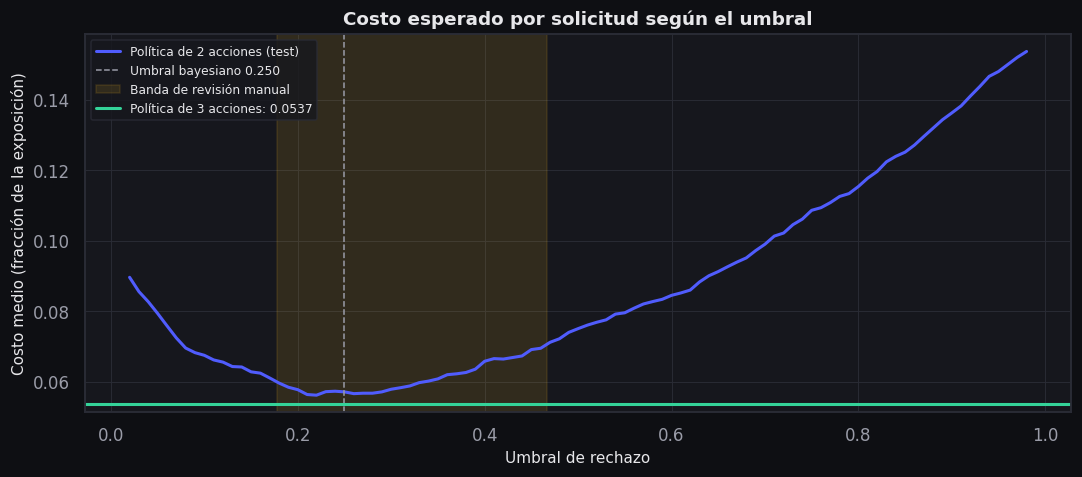

In [7]:
costos = Costos(fn=card["costos"]["lgd_fn"], fp=card["costos"]["margen_fp"], revision=card["costos"]["revision"])
curva = costo_binario(y_te, p_cal, costos)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curva["umbral"], curva["costo_medio"], color=PALETA["acento"], lw=2, label="Política de 2 acciones (test)")
ax.axvline(U.bayes, color=PALETA["texto_suave"], ls="--", lw=1, label=f"Umbral bayesiano {U.bayes:.3f}")
ax.axvspan(U.aprobar, U.rechazar, color=PALETA["medio"], alpha=0.12, label="Banda de revisión manual")
ax.axhline(card["decision_test"]["costo_medio"], color=PALETA["bajo"], lw=2,
           label=f"Política de 3 acciones: {card['decision_test']['costo_medio']:.4f}")
ax.set(title="Costo esperado por solicitud según el umbral", xlabel="Umbral de rechazo",
       ylabel="Costo medio (fracción de la exposición)")
ax.legend(fontsize=8)
plt.show()
figura_front("lineas", "Costo esperado por solicitud según el umbral",
             {"series": [{"nombre": "Política de 2 acciones (test)", "x": curva["umbral"].round(2).tolist(),
                          "y": curva["costo_medio"].round(5).tolist()}],
              "referencias": [{"eje": "x", "valor": round(U.bayes, 4), "etiqueta": "Umbral bayesiano"},
                              {"eje": "y", "valor": card["decision_test"]["costo_medio"], "etiqueta": "Política de 3 acciones"}],
              "bandas": [{"desde": round(U.aprobar, 4), "hasta": round(U.rechazar, 4), "etiqueta": "Revisión manual"}]},
             ejes={"x": "Umbral de rechazo", "y": "Costo medio (fracción de la exposición)"}, clave="curva_costo",
             opciones={"formato_x": "pct", "formato_y": "dec3"})

**Interpretación.** La curva es el costo de una política de solo aprobar/rechazar: su mínimo empírico en test
(0,0563 por solicitud) está en el umbral 0,22, cerca del bayesiano teórico 0,25. La franja ámbar es la zona
donde revisar a mano cuesta menos que equivocarse; la línea de la política de tres acciones (0,0537) queda por
debajo de todo el mínimo de dos acciones: la banda de revisión ahorra un 4,5 % adicional frente al mejor umbral
posible y un 6,1 % frente al bayesiano.

In [8]:
decision = pd.Series(card["decision_test"]).to_frame("test")
sens = pd.DataFrame(card["sensibilidad_umbrales"])
display(decision)
sens

,test
costo_medio,0.0537
tasa_aprobacion,0.3971
tasa_revision,0.2883
tasa_rechazo,0.3146
impago_en_aprobados,0.0976
supera_capacidad_revision,False


,lgd,margen,aprobar_si_p_menor,rechazar_si_p_mayor,banda_revision
0,0.4500,0.1000,0.1778,0.2000,True
1,0.4500,0.1500,0.1778,0.4667,True
2,0.4500,0.2000,0.1778,0.6000,True
3,0.5500,0.1000,0.1455,0.2000,True
4,0.5500,0.1500,0.1455,0.4667,True
5,0.5500,0.2000,0.1455,0.6000,True
6,0.6500,0.1000,0.1231,0.2000,True
7,0.6500,0.1500,0.1231,0.4667,True
8,0.6500,0.2000,0.1231,0.6000,True
9,0.7500,0.1000,0.1067,0.2000,True


**Interpretación.** En test se aprueba automáticamente el 39,7 %, se revisa el 28,8 % (por debajo de la
capacidad de alerta del 35 %) y se rechaza el 31,5 %; entre los aprobados el impago cae al 9,8 %, frente al
35,6 % de la cartera. La sensibilidad muestra que con LGD más alta el umbral de aprobación baja (0,178 → 0,107)
y con margen más alto el de rechazo sube (0,20 → 0,60): la política responde a los supuestos de negocio.

## 4. Comparación final de todos los modelos

Clásicos (paso 5), redes neuronales (paso 6), NLP (paso 7), Spark MLlib (paso 9) y el modelo servido,
con las mismas métricas sobre el mismo test.

In [9]:
filas = []
for nombre in ["resultados_clasicos", "resultados_dl", "resultados_nlp", "resultados_spark"]:
    ruta = config.MODEL_DIR / f"{nombre}.json"
    if ruta.exists():
        for f in leer_json(ruta)["modelos"]:
            filas.append({"modelo": f["modelo"], "familia": f["familia"], **f["test"],
                          "tiempo_s": f.get("tiempo_entrenamiento_s"), "interpretabilidad": f["interpretabilidad"]})
filas.append({"modelo": f"Servido v{card['version']} ({card['familia']}, calibrado)", "familia": "final",
              **metricas(y_te, p_cal, U.bayes), "tiempo_s": card["duracion_entrenamiento_s"], "interpretabilidad": "alta"})
comparacion = pd.DataFrame(filas).sort_values("roc_auc", ascending=False).reset_index(drop=True)
comparacion

,modelo,familia,roc_auc,pr_auc,ks,brier,accuracy,precision,recall,f1,tiempo_s,interpretabilidad
0,Combinado: tabular + sentimiento + PCA(10) ST,nlp,0.8471,0.7695,0.5550,0.1481,0.7354,0.5900,0.8407,0.6934,4.6100,media
1,Regresión logística,clásico,0.8459,0.7680,0.5445,0.1488,0.7325,0.5860,0.8454,0.6922,0.9100,alta
2,"Servido v2.0.0 (Regresión logística, calibrado)",final,0.8456,0.7675,0.5384,0.1491,0.7329,0.5872,0.8396,0.6911,490.1000,alta
3,Regresión logística (Spark MLlib),big data,0.8441,0.7686,0.5532,0.1493,0.7304,0.5844,0.8396,0.6891,27.9100,alta
4,MLP (Keras),deep learning,0.8419,0.7632,0.5353,0.1509,0.7104,0.5610,0.8560,0.6778,27.8000,baja
5,Hibrido (Keras),deep learning,0.8399,0.7559,0.5360,0.1531,0.7196,0.5719,0.8431,0.6815,62.2000,baja
6,Random Forest,clásico,0.8397,0.7556,0.5335,0.1526,0.7092,0.5593,0.8618,0.6783,5.5100,media
7,Gradient Boosting (HGB),clásico,0.8290,0.7416,0.5069,0.1592,0.7229,0.5787,0.8138,0.6764,34.4400,media
8,Árbol de decisión,clásico,0.8207,0.7274,0.4862,0.1613,0.7113,0.5657,0.8115,0.6667,1.2700,alta
9,CNN1D (Keras),deep learning,0.7709,0.6805,0.4144,0.1795,0.5700,0.4474,0.8864,0.5947,75.8000,baja


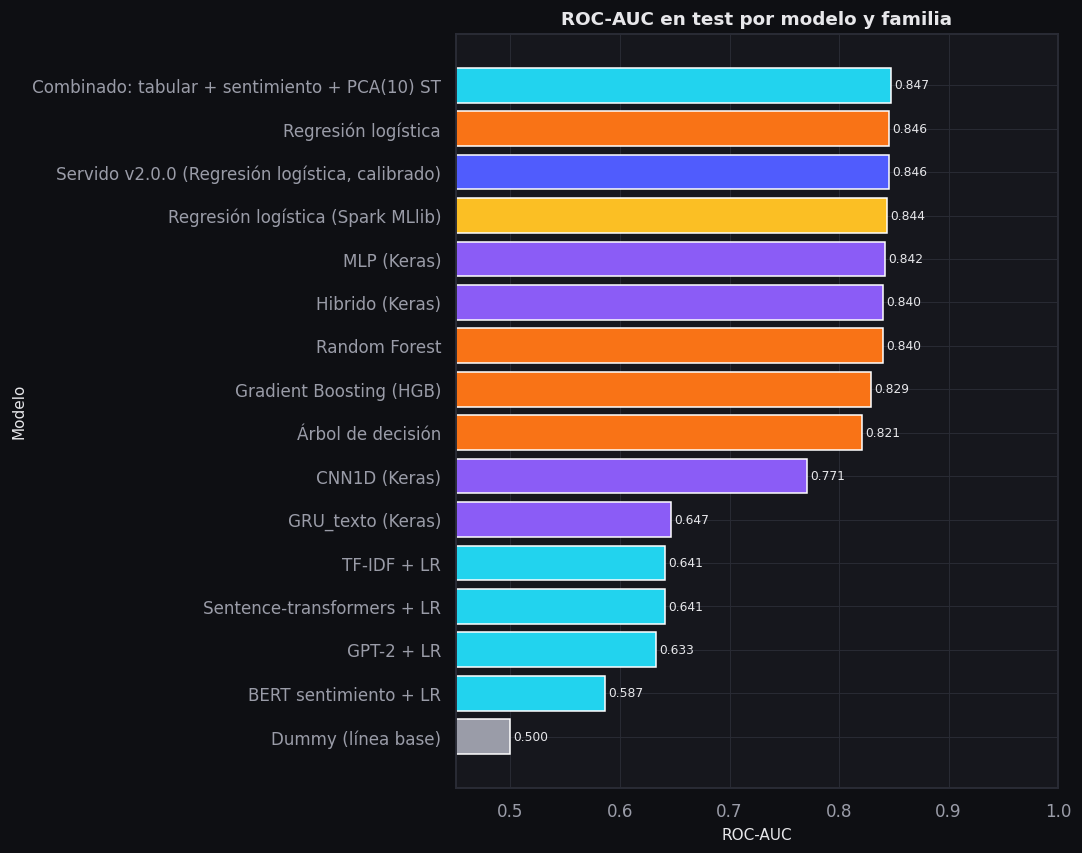

In [10]:
colores = {"línea base": PALETA["texto_suave"], "clásico": PALETA["programacion"], "deep learning": PALETA["ia"],
           "nlp": "#22D3EE", "big data": PALETA["medio"], "final": PALETA["acento"]}
d = comparacion.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.2))
ax.barh(d["modelo"], d["roc_auc"], color=[colores[f] for f in d["familia"]])
for i, v in enumerate(d["roc_auc"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
ax.set(title="ROC-AUC en test por modelo y familia", xlabel="ROC-AUC", ylabel="Modelo", xlim=(0.45, 1))
plt.show()
figura_front("barras_h", "ROC-AUC en test por modelo y familia",
             {"categorias": d["modelo"].tolist(), "series": [{"nombre": "ROC-AUC", "valores": d["roc_auc"].round(4).tolist()}],
              "familias": d["familia"].tolist()},
             ejes={"x": "ROC-AUC", "y": "Modelo"}, clave="comparacion_final", opciones={"color_por": "familia", "min_x": 0.45})

**Interpretación.** Dieciséis modelos de cinco familias sobre el mismo test. El combinado con texto encabeza
(AUC 0,847), con una ventaja sobre el tabular que el IC no distingue de cero (ΔAUC +0,0012, IC 95 %
[−0,0003; +0,0028]); por eso se sirve el modelo tabular, más simple (paso 7). El servido (0,8456)
prácticamente iguala a la logística clásica (0,8459): la mitigación de equidad y la calibración cuestan menos
de una milésima de AUC. Spark MLlib (0,844, la misma regresión logística entrenada de forma distribuida) y las
redes (MLP 0,842) no superan al modelo lineal de scikit-learn, que además es el más interpretable y barato de servir.

## 5. Auditoría de equidad (IA1.3)

El DI se mide sobre la **aprobación automática**. Primero, las variantes evaluadas con predicciones
out-of-fold en train (la elección no usa test); luego, la medición final en test con IC bootstrap.

In [11]:
variantes = pd.DataFrame(card["variantes_equidad"])
variantes[["variante", "roc_auc_oof", "costo_medio", "precio_equidad_costo", "tasa_aprobacion", "di_sexo", "di_edad",
           "cumple_equidad"]]

,variante,roc_auc_oof,costo_medio,precio_equidad_costo,tasa_aprobacion,di_sexo,di_edad,cumple_equidad
0,base,0.8579,0.0500,0.0000,0.3816,0.9788,0.7207,False
1,sin_edad,0.8582,0.0498,-0.0003,0.3817,0.9837,0.7099,False
2,reweighing,0.8570,0.0503,0.0003,0.3807,0.9811,0.8924,True


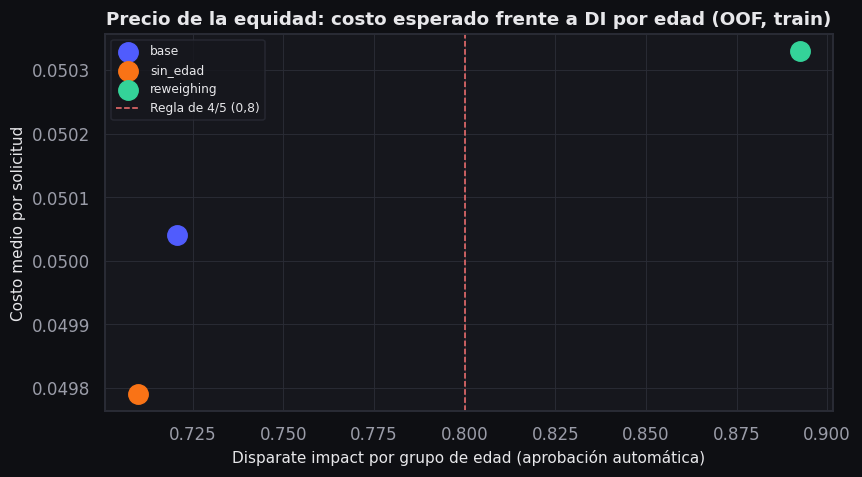

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (_, v), color in zip(variantes.iterrows(), SERIE):
    ax.scatter(v["di_edad"], v["costo_medio"], s=160, color=color, label=v["variante"], zorder=3)
ax.axvline(config.DI_MINIMO, color=PALETA["alto"], ls="--", lw=1, label="Regla de 4/5 (0,8)")
ax.set(title="Precio de la equidad: costo esperado frente a DI por edad (OOF, train)",
       xlabel="Disparate impact por grupo de edad (aprobación automática)", ylabel="Costo medio por solicitud")
ax.legend(fontsize=8)
plt.show()
figura_front("dispersion", "Precio de la equidad: costo esperado frente a DI por edad (OOF, train)",
             {"series": [{"nombre": v["variante"], "puntos": [[v["di_edad"], v["costo_medio"]]]} for _, v in variantes.iterrows()],
              "referencias": [{"eje": "x", "valor": config.DI_MINIMO, "etiqueta": "Regla de 4/5"}]},
             ejes={"x": "Disparate impact por edad (aprobación automática)", "y": "Costo medio por solicitud"},
             clave="precio_equidad", opciones={"formato_y": "dec3", "tamano_punto": 18})

**Interpretación.** Cada punto es una variante del modelo. Quitar la edad (sin_edad) no mejora la equidad por
edad (DI 0,72 → 0,71): la disparidad viaja por variables legítimas como ingreso y antigüedad. El reweighing sí
la lleva a 0,89, a la derecha de la regla de 4/5, con un "precio de la equidad" de +0,0003 de costo esperado por
solicitud (+0,6 %): por eso es la variante servida.

In [13]:
for atributo in ["sexo", "edad"]:
    e = card["equidad_test"][atributo]
    display(Markdown(f"**{atributo.capitalize()}** · DI {e['disparate_impact']} (IC 95 % {e['di_ic95']}) · "
                     f"DI igualdad de oportunidades {e['di_igualdad_oportunidades']} · cumple 4/5: {e['cumple_regla_80']}"))
    display(pd.DataFrame(e["grupos"]).set_index("grupo"))

**Sexo** · DI 0.9696 (IC 95 % [0.8682, 0.9974]) · DI igualdad de oportunidades 0.963 · cumple 4/5: True

,n,tasa_aprobacion,aprobacion_buenos_pagadores,rechazo_buenos_pagadores,prob_media,tasa_impago_real,error_calibracion,cuenta_para_di
grupo,,,,,,,,
F,1182,0.3909,0.5456,0.1334,0.3517,0.3596,-0.0079,True
M,1218,0.4031,0.5665,0.1394,0.3471,0.3522,-0.0051,True


**Edad** · DI 0.8955 (IC 95 % [0.7803, 0.9771]) · DI igualdad de oportunidades 0.9373 · cumple 4/5: True

,n,tasa_aprobacion,aprobacion_buenos_pagadores,rechazo_buenos_pagadores,prob_media,tasa_impago_real,error_calibracion,cuenta_para_di
grupo,,,,,,,,
18-29,474,0.3734,0.5311,0.1443,0.3495,0.3565,-0.0070,True
30-59,1161,0.3936,0.5595,0.1368,0.3533,0.3704,-0.0170,True
60+,765,0.4170,0.5667,0.1314,0.3432,0.3333,0.0099,True


**Interpretación.** En test, el DI por sexo es 0,970 y por edad 0,896; entre buenos pagadores (igualdad de
oportunidades) 0,963 y 0,937. El error de calibración por grupo es pequeño (máximo 1,7 puntos en 30-59 años):
las diferencias de aprobación que quedan reflejan diferencias reales de riesgo, no un modelo mal calibrado para
un grupo. El IC 95 % del DI por edad es [0,78; 0,98] y se recalcula en cada cosecha como parte de la operación.

## 6. Explicabilidad: global (SHAP) y tres casos individuales

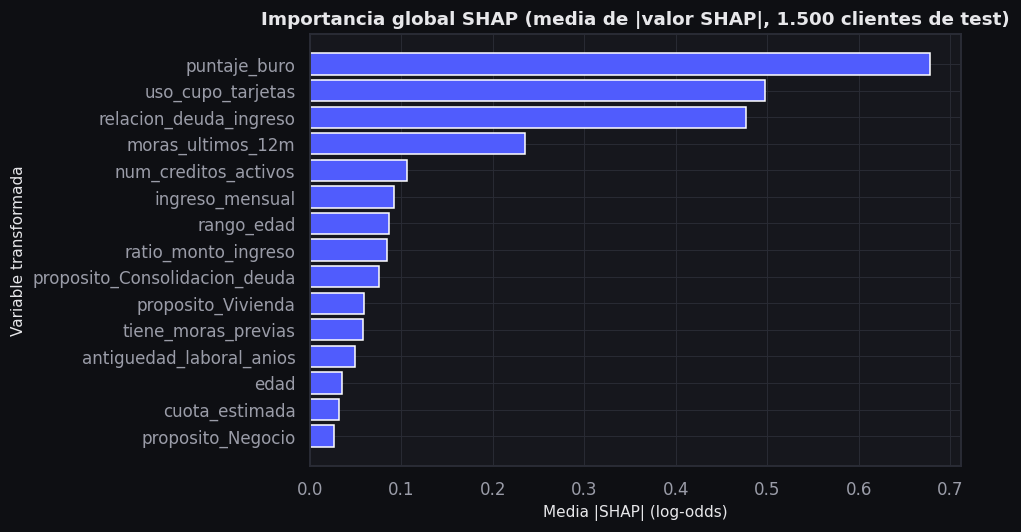

In [14]:
import shap

pipe = estimador_base(artefacto.modelo)
pipe = getattr(pipe, "estimator_", pipe)
Z_tr = pipe.named_steps["preprocessor"].transform(pipe.named_steps["capping"].transform(pipe.named_steps["features"].transform(X_tr)))
Z_te = pipe.named_steps["preprocessor"].transform(pipe.named_steps["capping"].transform(pipe.named_steps["features"].transform(X_te.head(1500))))
nombres = pipe.named_steps["preprocessor"].get_feature_names_out()
if hasattr(pipe.named_steps["model"], "coef_"):
    explainer = shap.LinearExplainer(pipe.named_steps["model"], Z_tr)
else:
    explainer = shap.TreeExplainer(pipe.named_steps["model"])
sv = explainer.shap_values(Z_te)
sv = sv[1] if isinstance(sv, list) else sv
global_ = pd.Series(np.abs(sv).mean(axis=0), index=nombres).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(global_.index, global_.values, color=PALETA["acento"])
ax.set(title="Importancia global SHAP (media de |valor SHAP|, 1.500 clientes de test)", xlabel="Media |SHAP| (log-odds)",
       ylabel="Variable transformada")
plt.show()
figura_front("barras_h", "Importancia global SHAP (1.500 clientes de test)",
             {"categorias": global_.index.tolist(), "series": [{"nombre": "Media |SHAP|", "valores": global_.round(4).tolist()}]},
             ejes={"x": "Media |SHAP| (log-odds)", "y": "Variable"}, clave="shap_global")

**Interpretación.** SHAP reparte el log-odds de cada predicción entre las variables. Su ranking global
coincide con el de los coeficientes y la permutación del paso 5: tres métodos distintos señalan los mismos
factores, lo que da confianza en la explicación.

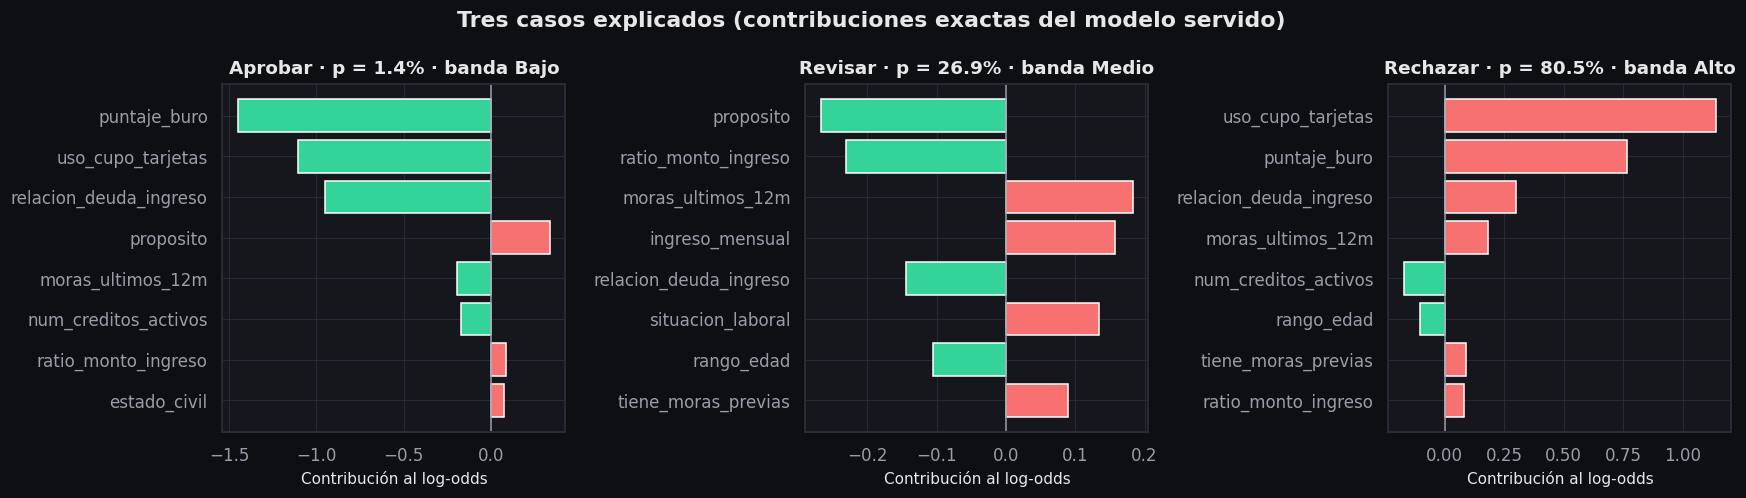

In [15]:
casos = {}
for d_ in ["aprobar", "revisar", "rechazar"]:
    idx = np.where(np.array([r["decision"] for r in artefacto.predecir(X_te.head(400).to_dict("records"))]) == d_)[0]
    casos[d_] = X_te.head(400).iloc[[idx[0]]] if len(idx) else None
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (d_, fila) in zip(axes, casos.items()):
    if fila is None:
        ax.set_visible(False)
        continue
    r = artefacto.predecir(fila.to_dict("records"), top_factores=8)[0]
    f = pd.DataFrame(r["factores_principales"]).iloc[::-1]
    ax.barh(f["variable"], f["contribucion"], color=np.where(f["contribucion"] > 0, PALETA["alto"], PALETA["bajo"]))
    ax.axvline(0, color=PALETA["texto_suave"], lw=1)
    ax.set(title=f"{d_.capitalize()} · p = {r['probabilidad_impago']:.1%} · banda {r['banda_riesgo']}",
           xlabel="Contribución al log-odds")
    figura_front("barras_h", f"Caso {d_}: p = {r['probabilidad_impago']:.1%} · banda {r['banda_riesgo']}",
                 {"categorias": f["variable"].tolist(), "series": [{"nombre": "Contribución", "valores": f["contribucion"].tolist()}]},
                 ejes={"x": "Contribución al log-odds", "y": "Variable"}, clave=f"caso_{d_}", opciones={"color_por": "signo"})
plt.suptitle("Tres casos explicados (contribuciones exactas del modelo servido)", fontweight="bold")
plt.show()

**Interpretación.** Cada barra es la contribución exacta de una variable al log-odds de la probabilidad
calibrada, frente al cliente promedio de train; la suma de todas más la base reproduce la probabilidad. Es
la misma explicación que devuelve la API y que muestra el simulador del front.

## 7. Monitoreo: estabilidad poblacional (PSI) entre train y test

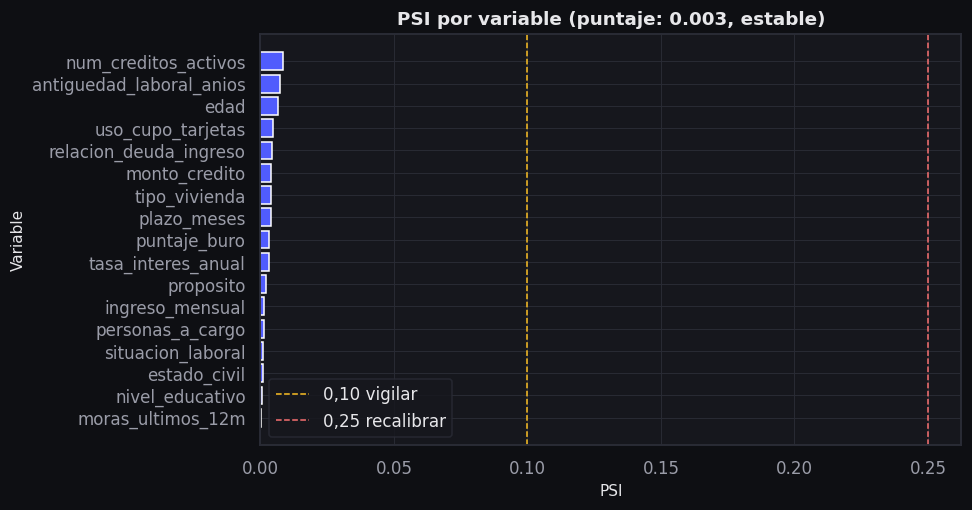

In [16]:
psi_vars = pd.DataFrame(card["monitoreo"]["psi_variables"])
fig, ax = plt.subplots(figsize=(9, 4.8))
d = psi_vars.sort_values("psi")
ax.barh(d["variable"], d["psi"], color=PALETA["acento"])
ax.axvline(config.PSI_ESTABLE, color=PALETA["medio"], ls="--", lw=1, label="0,10 vigilar")
ax.axvline(config.PSI_ALERTA, color=PALETA["alto"], ls="--", lw=1, label="0,25 recalibrar")
ax.set(title=f"PSI por variable (puntaje: {card['monitoreo']['psi_puntaje_train_test']}, {card['monitoreo']['estado']})",
       xlabel="PSI", ylabel="Variable")
ax.legend()
plt.show()
figura_front("barras_h", "PSI por variable (train frente a test)",
             {"categorias": d["variable"].tolist(), "series": [{"nombre": "PSI", "valores": d["psi"].tolist()}],
              "referencias": [{"eje": "x", "valor": config.PSI_ESTABLE, "etiqueta": "0,10 vigilar"},
                              {"eje": "x", "valor": config.PSI_ALERTA, "etiqueta": "0,25 recalibrar"}]},
             ejes={"x": "PSI", "y": "Variable"}, clave="psi_variables", opciones={"formato_x": "dec3"})

**Interpretación.** Todas las variables quedan muy por debajo de 0,10 (máximo 0,008) y el PSI del puntaje es
0,003: train y test son la misma población. Esta misma medición, aplicada mes a mes en producción, es la alarma
que dispara la recalibración (plan de operación en `docs/05_despliegue.md`).

## 8. Consistencia con la model card servida

In [17]:
recalculadas = metricas(y_te, p_cal, U.rechazar)
diferencias = {k: abs(recalculadas[k] - v) for k, v in card["metricas_test"].items()}
assert max(diferencias.values()) < 1e-9, diferencias
assert np.allclose(artefacto.modelo.predict_proba(X_te)[:, 1], p_cal)
print("✔ Las métricas recalculadas desde test_predictions.parquet coinciden con model_card.json")
print("✔ El artefacto servido reproduce exactamente las probabilidades de test guardadas")
display(Markdown(
    f"**Resumen calculado.** Modelo servido v{card['version']} ({card['algoritmo']}), variante "
    f"`{card['variante_equidad']}`. Test: AUC {card['metricas_test']['roc_auc']}, KS {card['metricas_test']['ks']}, "
    f"Brier {card['metricas_test']['brier']}. Decisiones en test: aprobar {card['decision_test']['tasa_aprobacion']:.1%}, "
    f"revisar {card['decision_test']['tasa_revision']:.1%}, rechazar {card['decision_test']['tasa_rechazo']:.1%}; "
    f"impago entre aprobados {card['decision_test']['impago_en_aprobados']:.1%}. DI edad "
    f"{card['equidad_test']['edad']['disparate_impact']}, DI sexo {card['equidad_test']['sexo']['disparate_impact']}."))

✔ Las métricas recalculadas desde test_predictions.parquet coinciden con model_card.json
✔ El artefacto servido reproduce exactamente las probabilidades de test guardadas


**Resumen calculado.** Modelo servido v2.0.0 (LogisticRegression calibrado (sigmoide, ensemble=False)), variante `reweighing`. Test: AUC 0.8456, KS 0.5384, Brier 0.1491. Decisiones en test: aprobar 39.7%, revisar 28.8%, rechazar 31.5%; impago entre aprobados 9.8%. DI edad 0.8955, DI sexo 0.9696.

## Conclusiones

1. **Optimización con disciplina:** la búsqueda aleatoria en train eligió la regresión logística (AUC CV 0,858)
   sobre el boosting (0,853); test se usó una sola vez y las cifras de este notebook coinciden con la card servida.
2. **Calibración verificada:** el modelo ya estaba calibrado (Brier 0,149); la calibración se conserva como
   garantía para la regla de decisión.
3. **Decisión con costos explícitos:** la política aprobar / revisar / rechazar ahorra un 6,1 % del costo
   esperado frente a la de dos acciones y deja un 9,8 % de impago entre los aprobados, con un 28,8 % de revisión.
4. **Equidad medida y mitigada:** el reweighing corrige la disparidad por edad (DI 0,72 → 0,90 en test) a un
   precio de 0,6 % de costo; sexo 0,97. Ambos DI se monitorean en operación con su IC.
5. **Explicable y estable:** SHAP, coeficientes y permutación coinciden (buró, cupo, deuda/ingreso, moras); cada
   decisión trae contribuciones exactas, y el PSI confirma una población estable.
6. **Elección final:** de 16 modelos comparados, se sirve la regresión logística calibrada con reweighing por
   su desempeño, su interpretabilidad, su equidad y su costo de servir (paso 10).